# Counterfactual Credit Fairness Under Uncertain Proxy Pathways
## Replication & Empirical Inspection Notebook
This notebook provides an interactive audit of data splits, candidate causal graphs ($G_1$–$G_4$), inference equivalence, live counterfactual query evaluation, and Pareto trade-off frontiers.

### 1. Environment & Diagnostic Setup

In [3]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import torch
from IPython.display import display, HTML

from src.causal_dags import build_candidate_dags, fit_bayesian_network, verify_inference_equivalence
from src.counterfactual import CounterfactualEngine
from src.models import MinimaxCounterfactualClassifier
from notebooks.generate_paper_figures import plot_pareto_frontier, plot_ablation_cross_graph, plot_simulation_thinning

print(f"PyTorch: {torch.__version__} | NumPy: {np.__version__} | Pandas: {pd.__version__}")
print("Deterministic Seed: 42")

/home/sh/Desktop/counterfactual-credit-fairness/notebooks/generate_paper_figures.py:46: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  ax2.set_ylabel("Worst-Case CF Shift ($\max_{G_k} \mathbb{E}[|\Delta f|]$)", color=color_shift)
/home/sh/Desktop/counterfactual-credit-fairness/notebooks/generate_paper_figures.py:53: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  ax1.annotate("Optimal Operating Point\n($\lambda = 0.60$)",


PyTorch: 2.14.1+cu130 | NumPy: 2.5.4 | Pandas: 3.1.1
Deterministic Seed: 42


### 2. Dataset Verification & Intersectional Strata Support Check
Verify the frozen 60/20/20 train/val/test partition and flag small intersectional cells ($N < 30$).

In [4]:
train_df = pd.read_csv("../data/processed/train.csv")
val_df   = pd.read_csv("../data/processed/val.csv")
test_df  = pd.read_csv("../data/processed/test.csv")

print(f"Split Sizes: Train={train_df.shape}, Val={val_df.shape}, Test={test_df.shape}")
assert len(train_df) == 18000 and len(val_df) == 6000 and len(test_df) == 6000, "Split size mismatch!"

group_counts = test_df["G"].value_counts().sort_index()
support_audit = pd.DataFrame({
    "Group_ID (A x C)": group_counts.index,
    "Count": group_counts.values,
    "Proportion": (group_counts.values / len(test_df)).round(4),
    "Small_Sample_Flag (N < 30)": group_counts.values < 30
})
display(support_audit)

Split Sizes: Train=(18000, 8), Val=(6000, 8), Test=(6000, 8)


,Group_ID (A x C),Count,Proportion,Small_Sample_Flag (N < 30)
0,0,1143,0.1905,False
1,1,1126,0.1877,False
2,2,108,0.0180,False
3,3,1997,0.3328,False
4,4,1524,0.2540,False
5,5,102,0.0170,False


### 3. Causal DAG Verification: Exact Inference Equivalence
Validates that Variable Elimination and Clique Tree (Belief Propagation) agree to within numerical tolerance ($\le 10^{-6}$) on all 4 candidate DAGs.

In [5]:
dags = build_candidate_dags()
fitted_dags = {}
verification_rows = []

for name, model in dags.items():
    fitted = fit_bayesian_network(model, train_df)
    fitted_dags[name] = fitted
    agreed, max_diff, ve_val, bp_val = verify_inference_equivalence(fitted)
    verification_rows.append({
        "Candidate DAG": name,
        "Max VE vs. CT Difference": f"{max_diff:.2e}",
        "P(Y=1 | Evidence) [VE]": round(float(ve_val[1]), 5),
        "P(Y=1 | Evidence) [CT]": round(float(bp_val[1]), 5),
        "Passes Tolerance (<= 1e-6)": agreed
    })

display(pd.DataFrame(verification_rows))

,Candidate DAG,Max VE vs. CT Difference,P(Y=1 | Evidence) [VE],P(Y=1 | Evidence) [CT],Passes Tolerance (<= 1e-6)
0,G1_proxy_limit,5.55e-17,0.74104,0.74104,True
1,G2_unbiased_allocation,1.11e-16,0.74104,0.74104,True
2,G3_proxy_repayment,2.78e-17,0.79993,0.79993,True
3,G4_mediated_education,0.00e+00,0.74104,0.74104,True


### 4. Live Counterfactual Query Inspection Across Proxy Pathways
Inspects how intervening on recorded sex $do(A \leftarrow 1 - A)$ propagates through each DAG's proxy structure and affects predictive risk scores.

In [6]:
sample_client_df = test_df.iloc[[0]].copy()
target_a = 1 - int(sample_client_df["A"].values[0])

# Fit lightweight reference model to score factual vs graph-specific counterfactuals
ref_clf = MinimaxCounterfactualClassifier(input_dim=6, penalty_lambda=0.0, epochs=20, lr=0.01)
dummy_cfs = {g: sample_client_df for g in fitted_dags.keys()}
ref_clf.fit(sample_client_df, dummy_cfs)
factual_pred = float(ref_clf.predict_proba(sample_client_df)[0])

cf_pathway_records = []
for name, model in fitted_dags.items():
    engine = CounterfactualEngine(model)
    cf_df = engine.generate_counterfactual_dataset(sample_client_df, seed=42)
    cf_pred = float(ref_clf.predict_proba(cf_df)[0])
    
    cf_pathway_records.append({
        "Candidate DAG": name,
        "Factual (A, L, R)": f"({int(sample_client_df['A'].values[0])}, {int(sample_client_df['L'].values[0])}, {int(sample_client_df['R'].values[0])})",
        "Counterfactual (A, L, R)": f"({int(cf_df['A'].values[0])}, {int(cf_df['L'].values[0])}, {int(cf_df['R'].values[0])})",
        "Factual Risk Score": round(factual_pred, 4),
        "CF Risk Score": round(cf_pred, 4),
        "Path-Specific Score Shift": round(abs(factual_pred - cf_pred), 4)
    })

display(pd.DataFrame(cf_pathway_records))

,Candidate DAG,"Factual (A, L, R)","Counterfactual (A, L, R)",Factual Risk Score,CF Risk Score,Path-Specific Score Shift
0,G1_proxy_limit,"(0, 2, 0)","(1, 1, 2)",0.9914,0.9899,0.0015
1,G2_unbiased_allocation,"(0, 2, 0)","(1, 1, 2)",0.9914,0.9956,0.0042
2,G3_proxy_repayment,"(0, 2, 0)","(1, 1, 2)",0.9914,0.9899,0.0015
3,G4_mediated_education,"(0, 2, 0)","(1, 1, 2)",0.9914,0.9956,0.0042


### 5. Experiment 2: Matched-Utility Pareto Frontier

Saved: figures/figure1_pareto_frontier.pdf


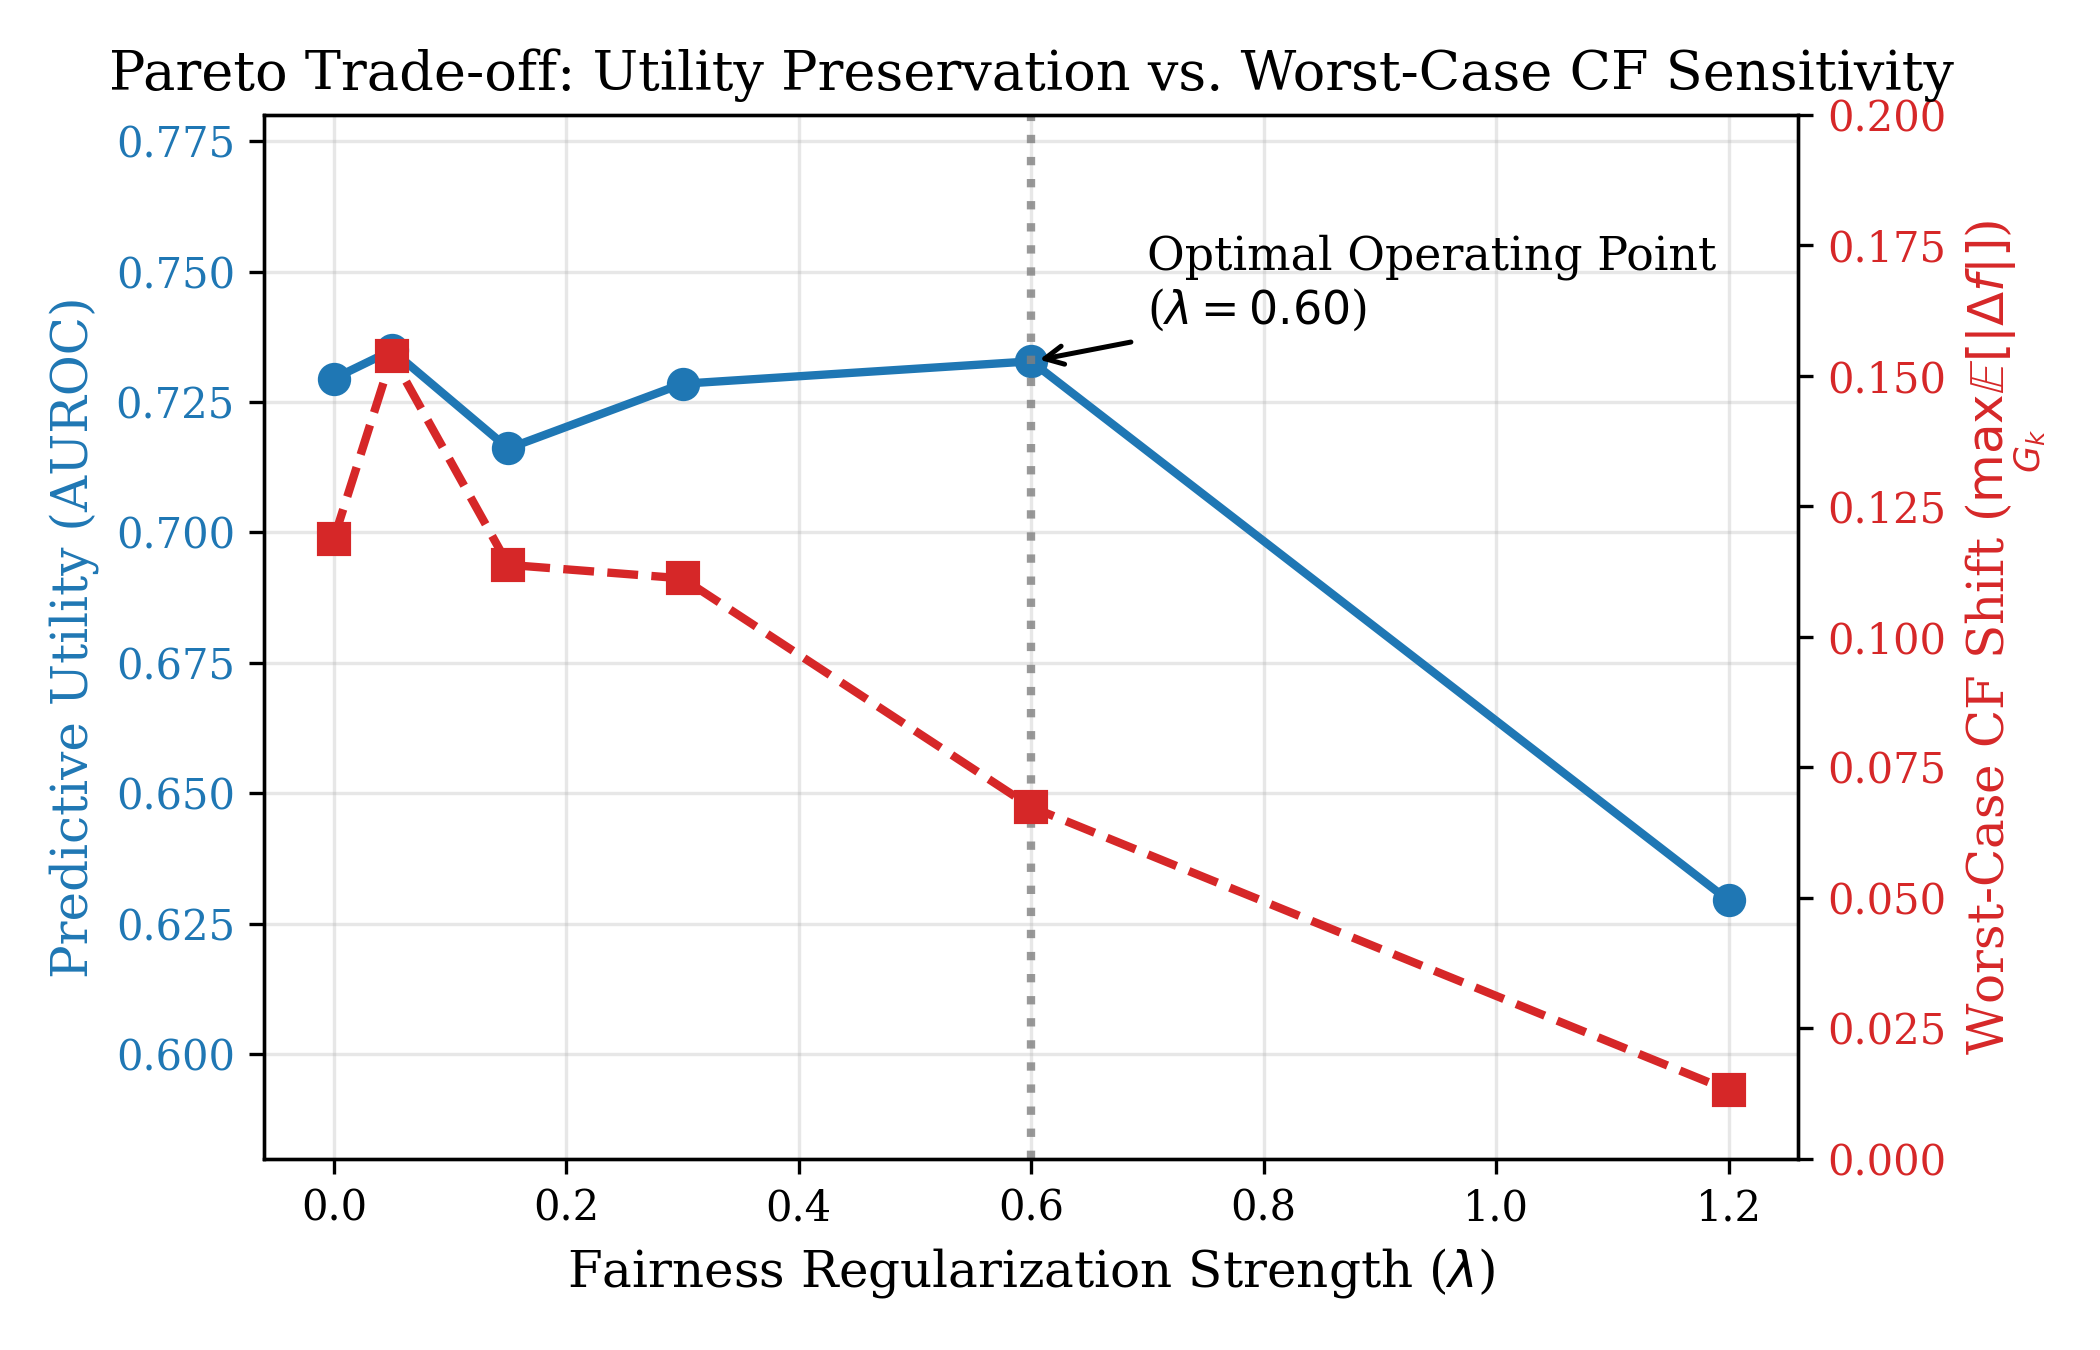

In [7]:
plot_pareto_frontier()
from IPython.display import Image
display(Image(filename="../figures/figure1_pareto_frontier.png"))

### 6. Experiment 3: Cross-Graph Ablation Discrepancy

Saved: figures/figure2_cross_graph_audit.pdf


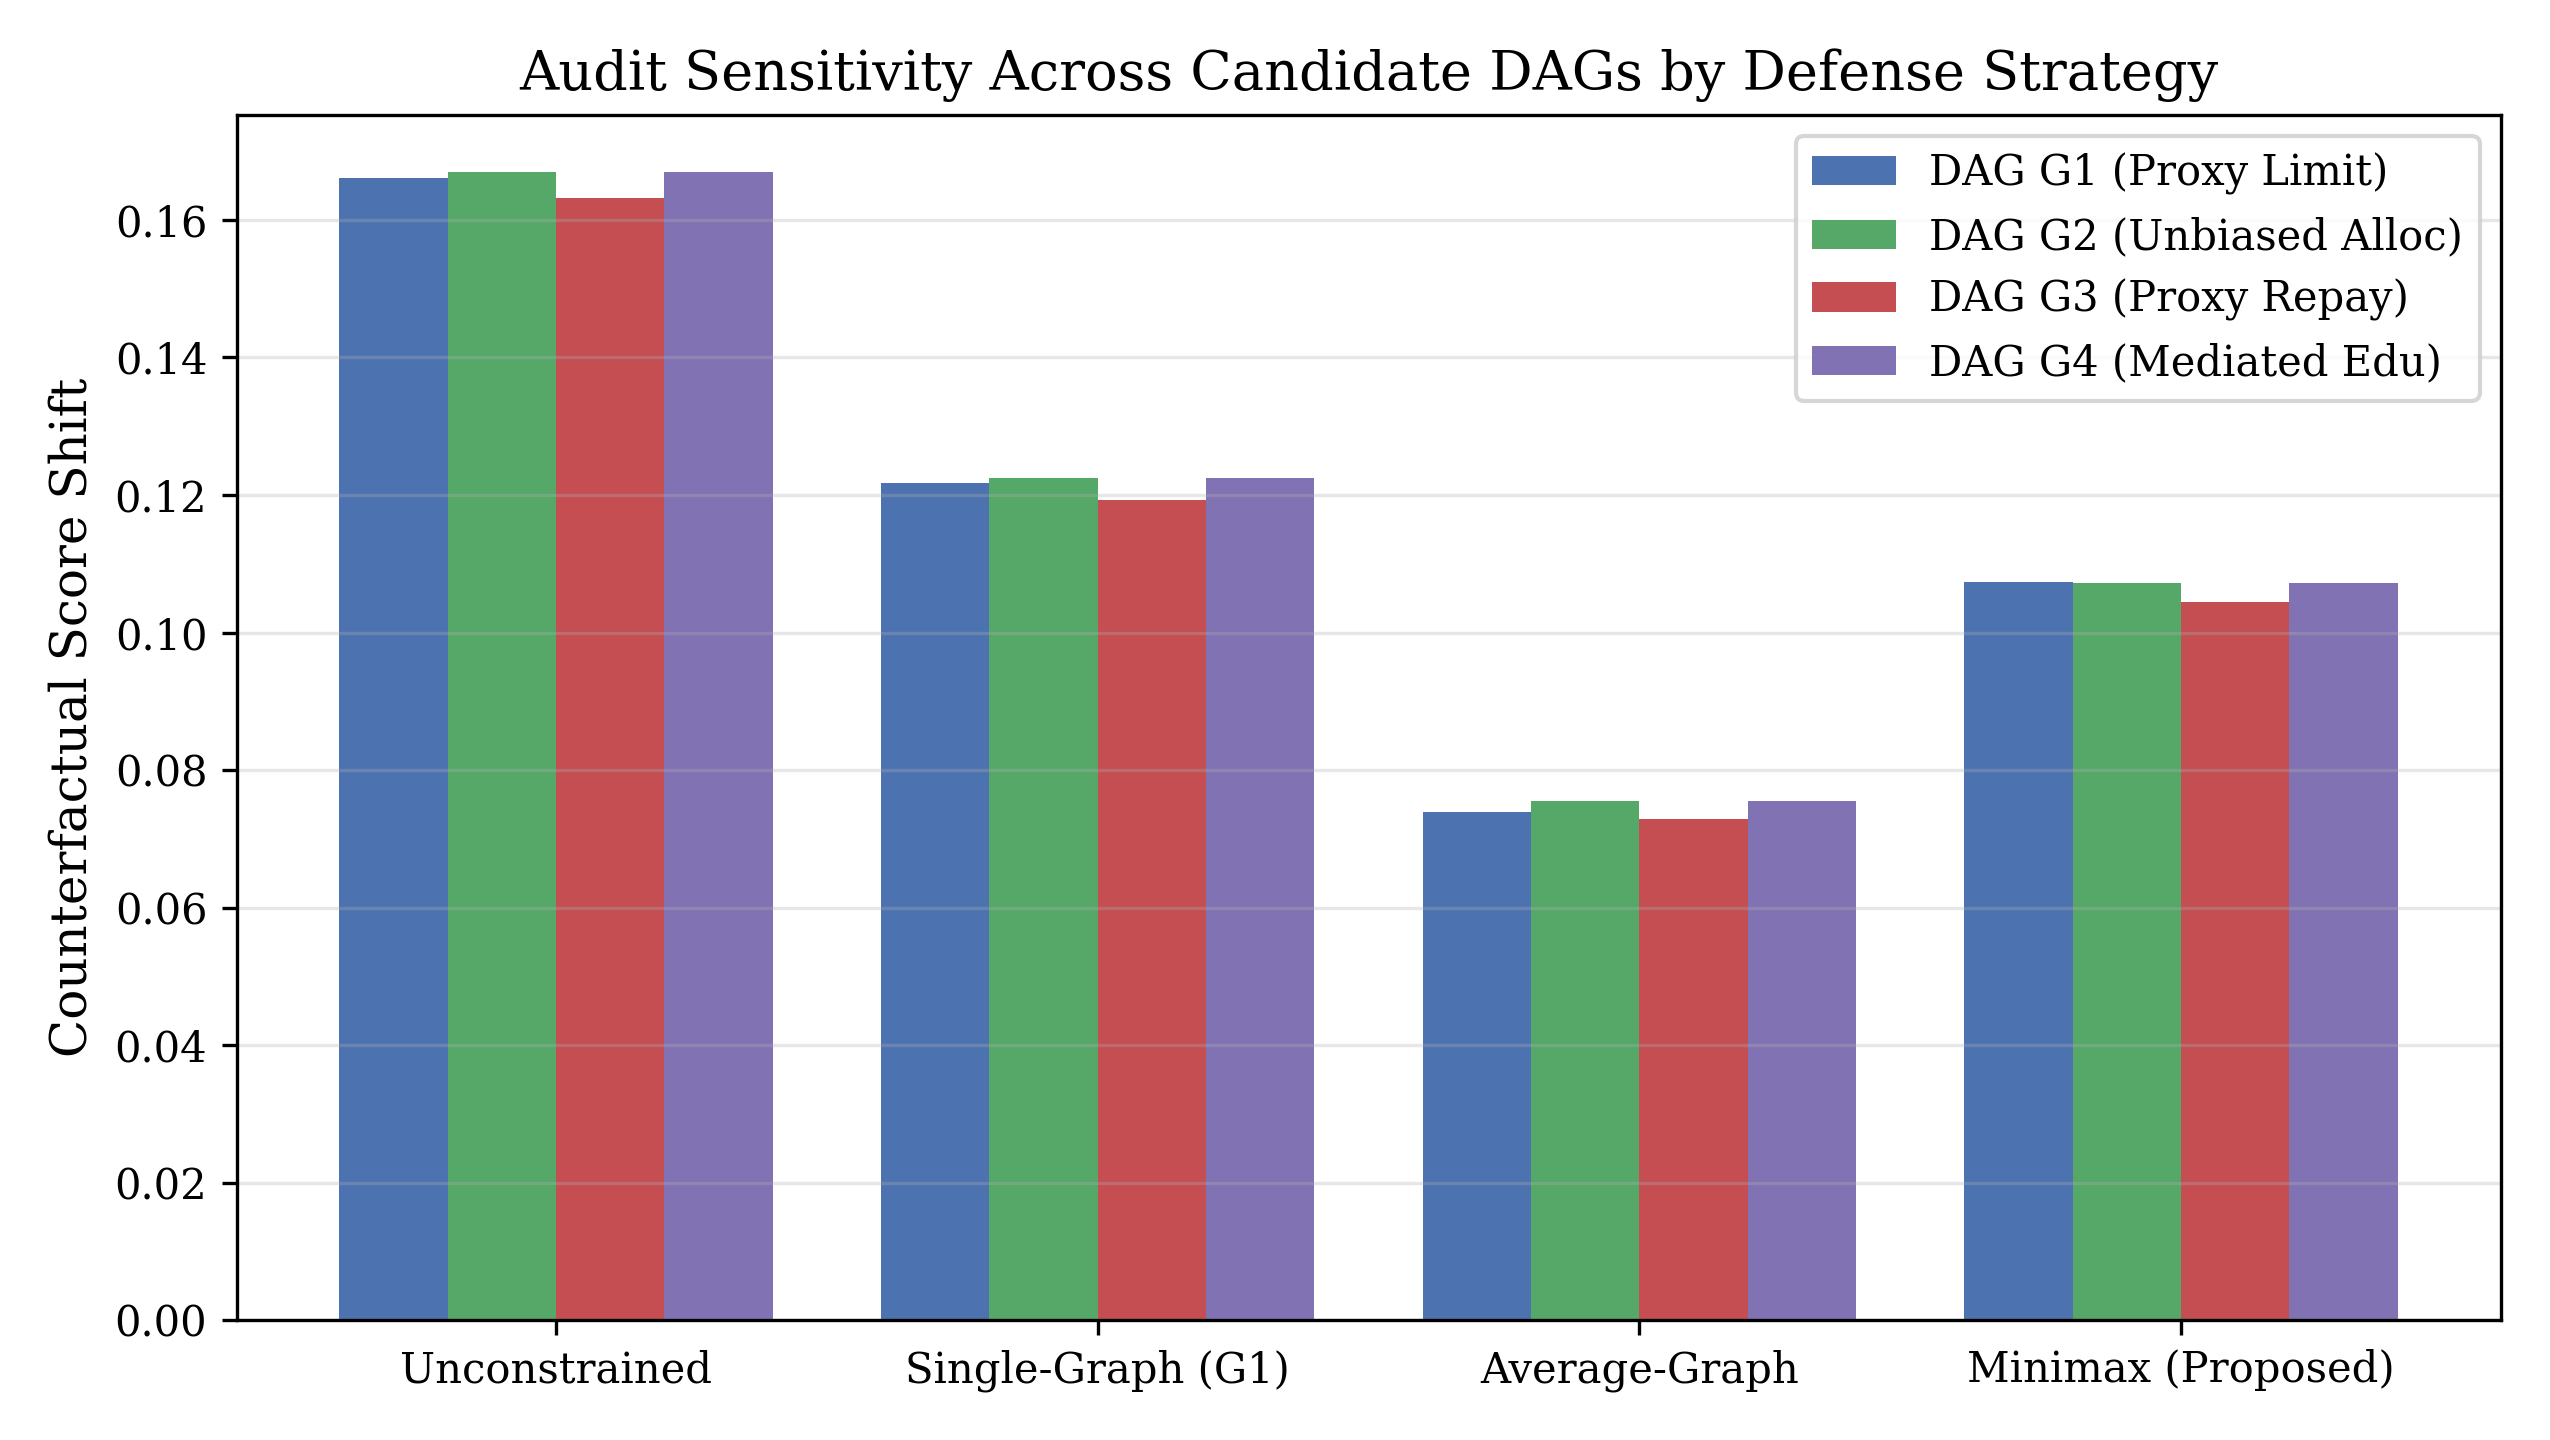

In [8]:
plot_ablation_cross_graph()
display(Image(filename="../figures/figure2_cross_graph_audit.png"))

### 7. Experiments 4 & 5: Simulation Stress-Testing & Graph Misspecification

Saved: figures/figure3_simulation_thinning.pdf


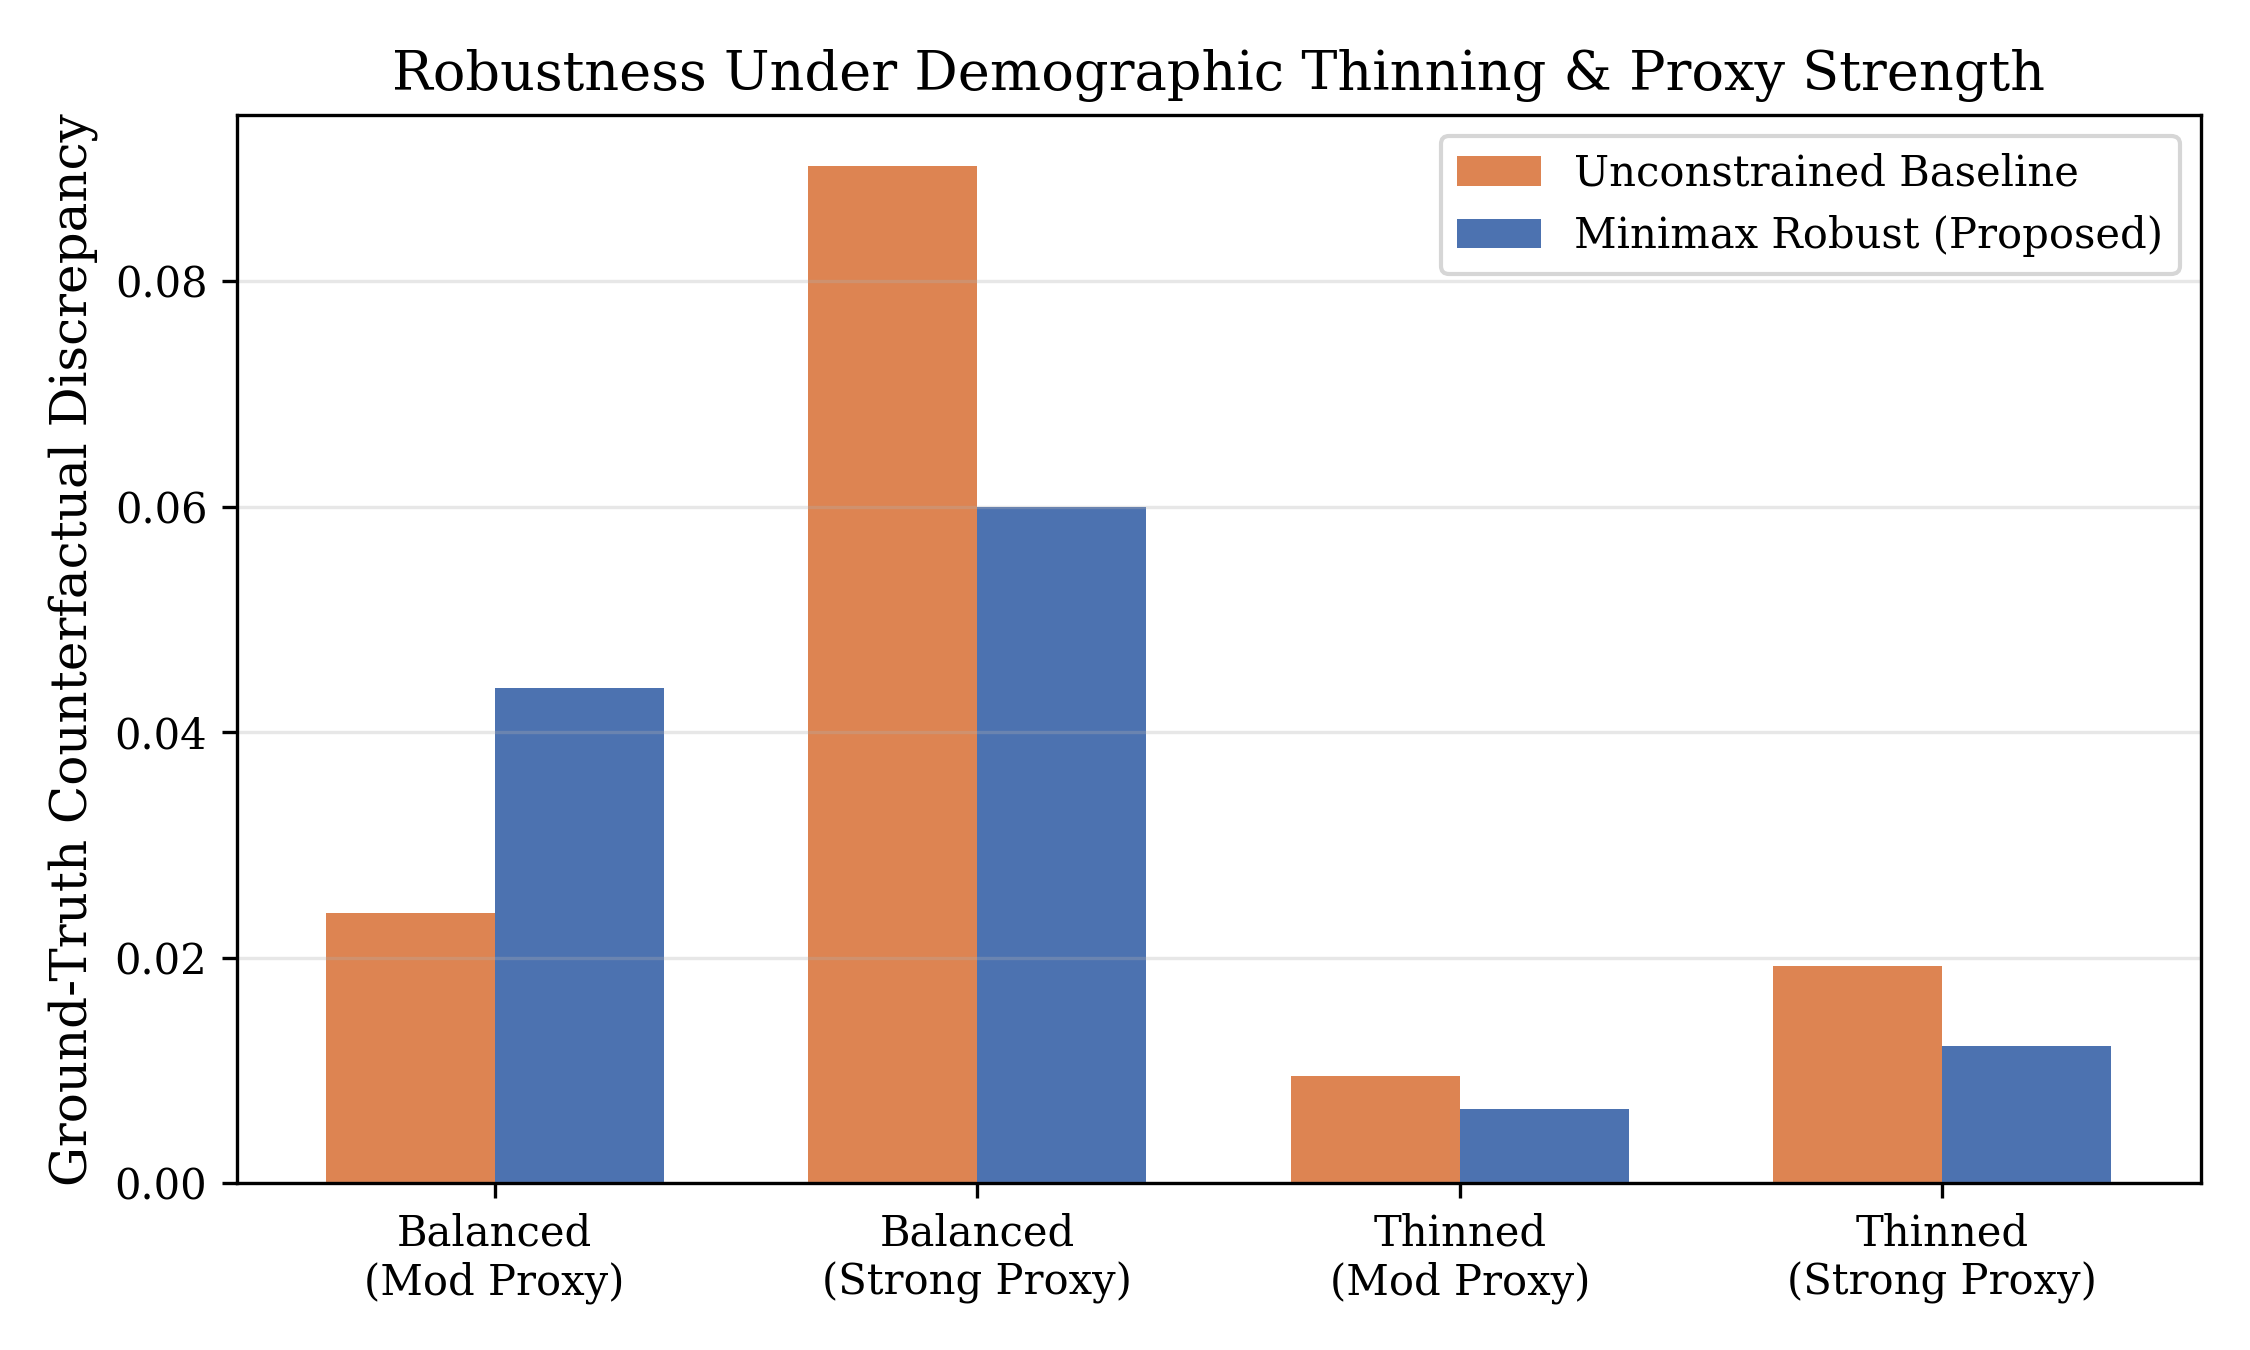

In [9]:
plot_simulation_thinning()
display(Image(filename="../figures/figure3_simulation_thinning.png"))